# Statistical tests of state-function decomposition in the LAI-aridity bins (as of 2026-11-24)

Each bin's contribution to the difference in domain-mean ET between a dataset (m) and the obs reference (r = `obs_pooled`), from `scripts/decompose_state_function.py` (`decomposition.decompose_binned`). With $a_b$ the fraction of the common land area in bin $b$ (the occupancy, `p` in the code), $f_b$ the bin-mean ET, both of the obs reference, and $\Delta$ the dataset minus the reference:

| term | per bin | in the code |
|---|---|---|
| $\Delta a_b \cdot f_b$ | $(a^m_b - a_b)\, f_b$ | `STATE` |
| $a_b \cdot \Delta f_b$ | $a_b\, (f^m_b - f_b)$ | `FUNCTION` |
| $\Delta a_b \cdot \Delta f_b$ | $(a^m_b - a_b)(f^m_b - f_b)$ | `INTERACTION` |

Their sum in each bin is $a^m_b f^m_b - a_b f_b$, and summed over the bins of the common support S (bins with ET in both m and r; NaN elsewhere) they are the terms of `decomp_vs_obs`, with STATE + FUNCTION + INTERACTION = `E_mm - E_rr`. Each value is a bin's share of the domain-mean ET difference [W m$^{-2}$].

### Formulation of statistical tests
**General form:**
$$
t = \frac{\text{observed difference}}{\text{standard error of that difference}}
$$

**Welch's two-sample t-test:**
assumes unequal population variances
$$
t = \frac{\bar{x} - \bar{y}}{\sqrt{s_x^2/n_x + s_y^2/n_y}}
$$

**Welch–Satterthwaite effective degrees of freedom:**
$$
\text{df} = \frac{\left( s_x^2/n_x + s_y^2/n_y \right)^2}{\frac{\left( s_x^2/n_x \right)^2}{n_x-1} + \frac{\left( s_y^2/n_y \right)^2}{n_y-1}}
$$

where $s$ is the per-bin sample standard deviation across $n$ products, so the squared standard error is $\text{SE}^2=s^2/n$.

#### FUNCTION ($a_b \cdot \Delta f_b$)
$$
t_b = \frac{f_{m,b} - \overline{f_{o,b}}}{\sqrt{s_{prod,b}^2(1+1/5) + s_{o,b}^2/n_{eff,o,b} + s_{m,b}^2/n_{eff,m,b}}}
$$

There are three variance terms: disagreement between obs products, model sampling of per-bin gridcells, and obs sampling of per-bin gridcells.

| Term                                	| Squared standard error, $\text{SE}_i^2=s_i^2/n_i$ 	| Degrees of freedom, $\nu_i$ 	| $i$ 	|
|-------------------------------------	|---------------------------------------	|-----------------------------	|-----	|
| Disagreement between obs products   	| $s_{prod,b}^2(1+1/5)$                 	| $n_{prod}-1$                	| 1   	|
| Obs sampling of per-bin gridcells   	| $s_{o,b}^2/n_{eff,o,b}$               	| $n_{eff,o,b}-1$             	| 2   	|
| Model sampling of per-bin gridcells 	| $s_{m,b}^2/n_{eff,m,b}$               	| $n_{eff,o,b}-1$             	| 3   	|

$s_{prod,b}^2(1+1/5)$ uses standard error following the prediction interval opposed to the confidence interval. The prediction interval estimates where a single future observation is likely to fall while the confidence interval estimates a population parameter, the mean.

1. [Confidence Interval vs Prediction Interval | Towards Data Science](https://towardsdatascience.com/confidence-interval-vs-prediction-interval-what-is-the-difference-64c45146d47d/)
2. [Prediction Intervals \| Harvard Business School](https://online.hbs.edu/blog/post/prediction-interval)

$$
\text{df}_b = \frac{(\text{SE}_1^2 + \text{SE}_2^2 + \text{SE}_3^2)^2}{\frac{\text{SE}_1^4}{\nu_1} + \frac{\text{SE}_2^4}{\nu_2} + \frac{\text{SE}_3^4}{\nu_3}}
$$

#### STATE ($\Delta a_b \cdot f_b$)


#### INTERACTION ($\Delta a_b \cdot \Delta f_b$)

### Main

### Supplement

In [1]:
import textwrap

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from scipy import stats

import etunc.config as cfg
import etunc.plotting as plotting

## 0. Preamble

### 0.1. Settings

In [2]:
RUN_ID = "r38cf3df"  # config/runs/aw_bins15.yml
_run = cfg.run_settings(RUN_ID)  # raises if RUN_ID is not registered

AREA_WEIGHTED = _run["binning"]["area_weighted"]
BIN_VARIABLE = _run["binning"]["bin_variable"]
EDGES = "pooled_all"
REFERENCE = "obs_pooled"  # obs reference of every term

# decompose_state_function.py needs a land-area weighted run of ET
if not AREA_WEIGHTED or BIN_VARIABLE != "et":
    raise ValueError(f"RUN_ID {RUN_ID} is not a land-area weighted run of et")

TIME_SLICE = slice(*_run["prep"]["time_slice"])
N_YBINS = _run["binning"]["n_ybins"]  # LAI
N_XBINS = _run["binning"]["n_xbins"]  # AI

FAMILIES = ["obs", "lsmobs", "cmip", "trendy_s3", "fppe", "ippe", "lens"]
DECOMP_FAMILIES = [f for f in FAMILIES if f != "obs"]  # the families compared with obs

print(f"RUN_ID: {RUN_ID}")
print(f"AREA_WEIGHTED: {AREA_WEIGHTED}")
print(f"BIN_VARIABLE: {BIN_VARIABLE}")
print(f"TIME_SLICE: {TIME_SLICE}")
print(f"N_YBINS: {N_YBINS}")
print(f"N_XBINS: {N_XBINS}")
print(f"REFERENCE: {REFERENCE}")

RUN_ID: r38cf3df
AREA_WEIGHTED: True
BIN_VARIABLE: et
TIME_SLICE: slice('2001-01', '2014-12', None)
N_YBINS: 15
N_XBINS: 15
REFERENCE: obs_pooled


In [3]:
DPI = 80

FAMILY_KWARGS = {
    "labels": {
        "obs": "OBS",
        "lsmobs": "ERA5/GLDAS",
        "cmip": "CMIP6",
        "fppe": "CESM2 FPPE",
        "ippe": "CESM2 IPPE",
        "lens": "CESM2 LENS",
        "trendy_s3": "TRENDY",
    },
    "colors": {
        "obs": "#000000",
        "lsmobs": "#989898",
        "cmip": "#EF476F",
        "fppe": "#118AB2",
        "ippe": "#09546D",
        "lens": "#FFD166",
        "trendy_s3": "#06D6A0",
    },
}

# The terms of decompose_binned, labelled in the notation of this notebook (a: land fraction, f: bin-mean ET)
TERMS = {
    "STATE": r"$\Delta a_b \cdot f_b$",
    "FUNCTION": r"$a_b \cdot \Delta f_b$",
    "INTERACTION": r"$\Delta a_b \cdot \Delta f_b$",
}
TOTAL_LABEL = r"$a^m_b f^m_b - a_b f_b$"  # the sum of the three terms in each bin

CMAP = "BrBG"  # brown: less ET than obs, green: more

### 0.2. Load the binned decomposition

In [4]:
def load_decomp_binned(family: str) -> xr.Dataset:
    # Each bin's contribution to the terms, every dataset of the family against REFERENCE (decompose_state_function.py)
    path = (cfg.output_dir(cfg.PROC_ROOT, "all", "decomp", RUN_ID)
            / f"all.{BIN_VARIABLE}_clim.decomp_binned.qbin_{EDGES}.{family}.{RUN_ID}.nc")
    if not path.exists():
        raise FileNotFoundError(f"No {path}; run decompose_state_function.py for run {RUN_ID} "
                                f"(ETUNC_RUN_ID={RUN_ID} pixi run decompose-state-function)")
    with xr.open_dataset(path) as ds:
        ds = ds[list(TERMS)].sel(obs_reference=REFERENCE).load()
    # Sum of the three terms in each bin: a^m f^m - a f on the common support
    ds["TOTAL"] = ds["STATE"] + ds["FUNCTION"] + ds["INTERACTION"]
    print(f"{family}: {ds.sizes['dataset']} datasets  {path}")
    return ds


decomp = {f: load_decomp_binned(f) for f in FAMILIES}

# Each family's members (models, products, ensemble members) and its <family>_pooled dataset, in which
# each group of variants weighs equally (FAMILY_POOL_WEIGHTING of decompose_state_function.py)
members = {f: d.isel(dataset=np.flatnonzero((d["source"] != "pooled").values)) for f, d in decomp.items()}
pooled = {f: decomp[f].sel(dataset=f"{f}_pooled") for f in DECOMP_FAMILIES}

obs: 4 datasets  /glade/work/bbuchovecky/et_unc/proc/r38cf3df/all/decomp/all.et_clim.decomp_binned.qbin_pooled_all.obs.r38cf3df.nc
lsmobs: 3 datasets  /glade/work/bbuchovecky/et_unc/proc/r38cf3df/all/decomp/all.et_clim.decomp_binned.qbin_pooled_all.lsmobs.r38cf3df.nc
cmip: 21 datasets  /glade/work/bbuchovecky/et_unc/proc/r38cf3df/all/decomp/all.et_clim.decomp_binned.qbin_pooled_all.cmip.r38cf3df.nc
trendy_s3: 17 datasets  /glade/work/bbuchovecky/et_unc/proc/r38cf3df/all/decomp/all.et_clim.decomp_binned.qbin_pooled_all.trendy_s3.r38cf3df.nc
fppe: 28 datasets  /glade/work/bbuchovecky/et_unc/proc/r38cf3df/all/decomp/all.et_clim.decomp_binned.qbin_pooled_all.fppe.r38cf3df.nc
ippe: 28 datasets  /glade/work/bbuchovecky/et_unc/proc/r38cf3df/all/decomp/all.et_clim.decomp_binned.qbin_pooled_all.ippe.r38cf3df.nc
lens: 51 datasets  /glade/work/bbuchovecky/et_unc/proc/r38cf3df/all/decomp/all.et_clim.decomp_binned.qbin_pooled_all.lens.r38cf3df.nc


In [5]:
# Check: summed over the bins, each term is that of decomp_vs_obs
vs_obs = xr.load_dataset(
    cfg.output_dir(cfg.PROC_ROOT, "all", "decomp", RUN_ID)
    / f"all.{BIN_VARIABLE}_clim.decomp_vs_obs.qbin_{EDGES}.{RUN_ID}.nc"
).sel(obs_reference=REFERENCE)

for f, d in decomp.items():
    for t in TERMS:
        err = float(abs(d[t].sum(["y_bin", "x_bin"]) - vs_obs[t].sel(dataset=d["dataset"])).max())
        if err > 1e-3:
            raise ValueError(f"{f} {t}: the sum over the bins differs from decomp_vs_obs by {err:.2g} W m-2")
print("Every term sums over the bins to its value in decomp_vs_obs")

Every term sums over the bins to its value in decomp_vs_obs


### 0.3. Load the binned stats

The land-area weighted `pooled_all` bin statistics of climatological ET from `scripts/bin_all_clim.py` in run `RUN_ID` (the inputs of the decomposition): per member, `(member, stats, y_bin, x_bin)` with `stats` = `mean`, `var_pop`, `var_samp`, `count`, `count_pos`, `sum_w`, `n_eff` (`binning.STATS`). `var_samp` and `n_eff` give the per-bin sampling terms $s^2_{b}$ and $n_{eff,b}$ of the tests.

In [59]:
def load_binned_stats(family: str) -> xr.DataArray:
    # Per-member bin statistics of climatological ET in run RUN_ID (bin_all_clim.py), as read by decompose_state_function.py
    path = (cfg.output_dir(cfg.PROC_ROOT, family, "qbin", RUN_ID)
            / f"{family}.{BIN_VARIABLE}_clim.qbin_{EDGES}.{RUN_ID}.nc")
    if not path.exists():
        raise FileNotFoundError(f"No {path}; run bin_all_clim.py for {family} in run {RUN_ID} "
                                "(ETUNC_RUN=<its run file> pixi run bin-all-clim)")
    bs = xr.load_dataarray(path)
    # Same inputs as the decomposition: land-area weights, the EDGES edges and the run's common area mask
    area_path = cfg.area_mask_path(RUN_ID)
    if (bs.attrs.get("weights") != "land_area" or bs.attrs.get("edges") != EDGES
            or bs.attrs.get("area_mask") != str(area_path)):
        raise ValueError(f"{path}: weights {bs.attrs.get('weights')}, edges {bs.attrs.get('edges')}, "
                         f"area mask {bs.attrs.get('area_mask')}; expected land_area, {EDGES}, {area_path}")
    print(f"{family}: {bs.sizes['member']} members, {len(set(bs['source'].values.tolist()))} sources  {path}")
    bs = bs.rename({"member": "dataset"})
    bs = bs.assign_coords(dataset=[family+"."+m.item() for m in bs.dataset.values])
    return bs


binned = {f: load_binned_stats(f) for f in FAMILIES}

obs: 4 members, 4 sources  /glade/work/bbuchovecky/et_unc/proc/r38cf3df/obs/qbin/obs.et_clim.qbin_pooled_all.r38cf3df.nc
lsmobs: 2 members, 2 sources  /glade/work/bbuchovecky/et_unc/proc/r38cf3df/lsmobs/qbin/lsmobs.et_clim.qbin_pooled_all.r38cf3df.nc
cmip: 20 members, 20 sources  /glade/work/bbuchovecky/et_unc/proc/r38cf3df/cmip/qbin/cmip.et_clim.qbin_pooled_all.r38cf3df.nc
trendy_s3: 16 members, 16 sources  /glade/work/bbuchovecky/et_unc/proc/r38cf3df/trendy_s3/qbin/trendy_s3.et_clim.qbin_pooled_all.r38cf3df.nc
fppe: 27 members, 27 sources  /glade/work/bbuchovecky/et_unc/proc/r38cf3df/fppe/qbin/fppe.et_clim.qbin_pooled_all.r38cf3df.nc
ippe: 27 members, 27 sources  /glade/work/bbuchovecky/et_unc/proc/r38cf3df/ippe/qbin/ippe.et_clim.qbin_pooled_all.r38cf3df.nc
lens: 50 members, 50 sources  /glade/work/bbuchovecky/et_unc/proc/r38cf3df/lens/qbin/lens.et_clim.qbin_pooled_all.r38cf3df.nc


### 0.4. Functions

In [45]:
def bin_ax(ax, da, xlabels=True, ylabels=True):
    # Bin edge ticks and AI/LAI labels of a (y_bin, x_bin) heatmap panel; tick labels only where asked
    plotting.set_edge_ticks(ax, da, "{:.2g}")
    ax.tick_params(labelsize=8, labelbottom=xlabels, labelleft=ylabels)
    ax.set_xlabel("Aridity, $R_n \\; / \\; L_vP$ $\\rightarrow$" if xlabels else "", fontsize=12)
    ax.set_ylabel("LAI [m$^2$/m$^2$] $\\rightarrow$" if ylabels else "", fontsize=12)

In [48]:
def member_panels(da, family, cbar_label, ncols=8, panel_size=2.2, extend="both", dim="dataset", **kwargs):
    n = da.sizes[dim]
    ncols = min(ncols, n)
    nrows = -(-n // ncols)
    fig, axes = plt.subplots(
        nrows=nrows,
        ncols=ncols,
        figsize=(panel_size * ncols + 1, panel_size * nrows + 1.5),
        layout="constrained",
        dpi=DPI,
        squeeze=False,
    )
    axs = axes.ravel()
    titles = (da["et_product"].values if family == "obs" else da["source"].values if family == "trendy_s3"
              else [str(d).split(".", 1)[1] for d in da[dim].values])
    for i in range(n):
        d = da.isel({dim: i})
        mp = d.plot(ax=axs[i], x="x_bin", y="y_bin", add_colorbar=False, add_labels=False, **kwargs)
        bin_ax(axs[i], d, xlabels=i + ncols >= n, ylabels=i % ncols == 0)
        axs[i].tick_params(labelsize=6)
        axs[i].set_title(textwrap.fill(str(titles[i]), 28), fontsize=9)  # long titles on several lines
    # Unused panels of the last row
    for ax in axs[n:]:
        ax.remove()

    # Colorbar half the width of wide figures, the full width of narrow ones, always ~0.2 in thick
    shrink = 0.5 if ncols > 2 else 1.0
    cb = fig.colorbar(mp, ax=axs[:n], location="bottom", shrink=shrink, aspect=shrink * panel_size * ncols / 0.2,
                      extend=extend)
    cb.ax.tick_params(labelsize=12)
    cb.set_label(cbar_label, fontsize=14)
    fig.suptitle(FAMILY_KWARGS["labels"][family], fontsize=16, fontweight="bold")
    return fig

## 1. Per-bin effective sample size

$$
n_{eff} = \frac{\left( \sum w_i \right)^2}{ \sum w_i^2}
$$

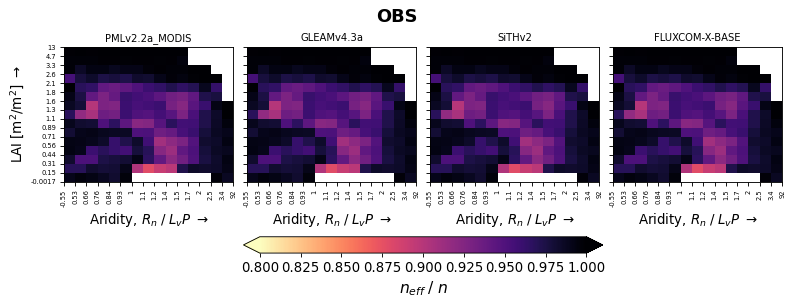

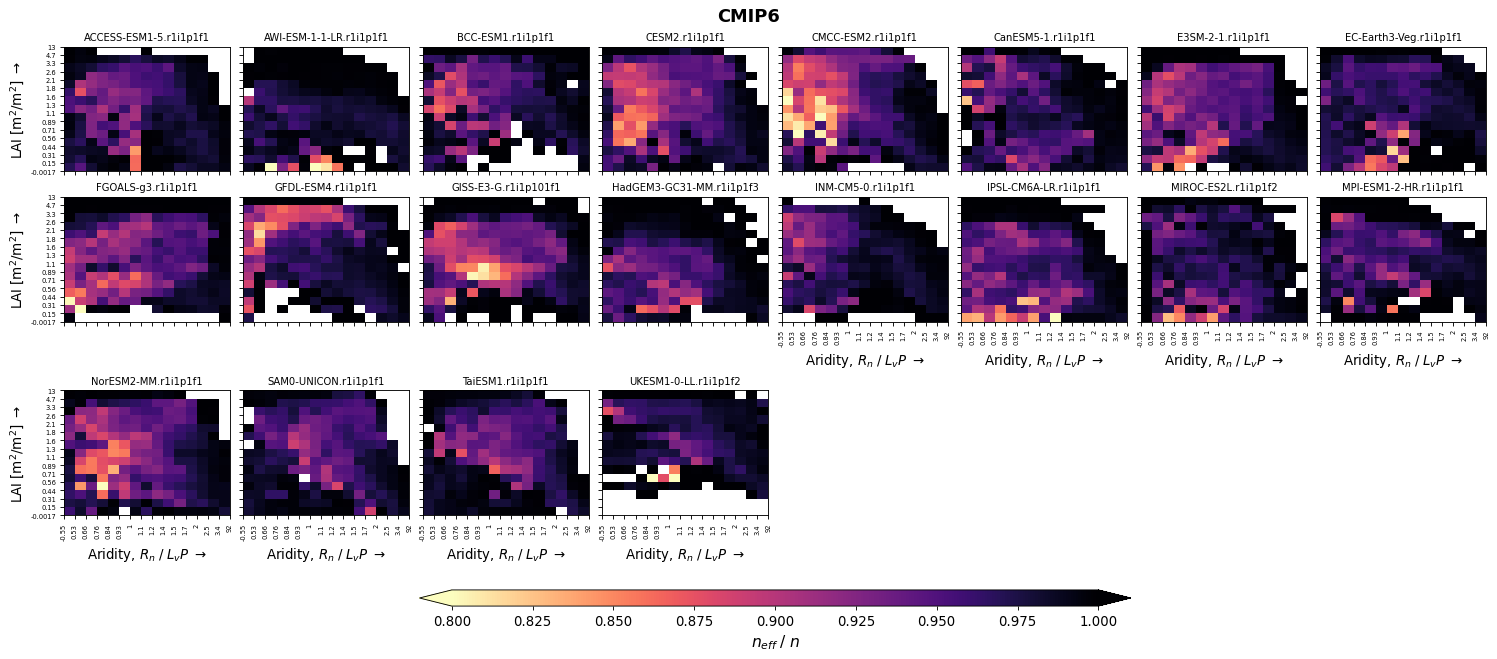

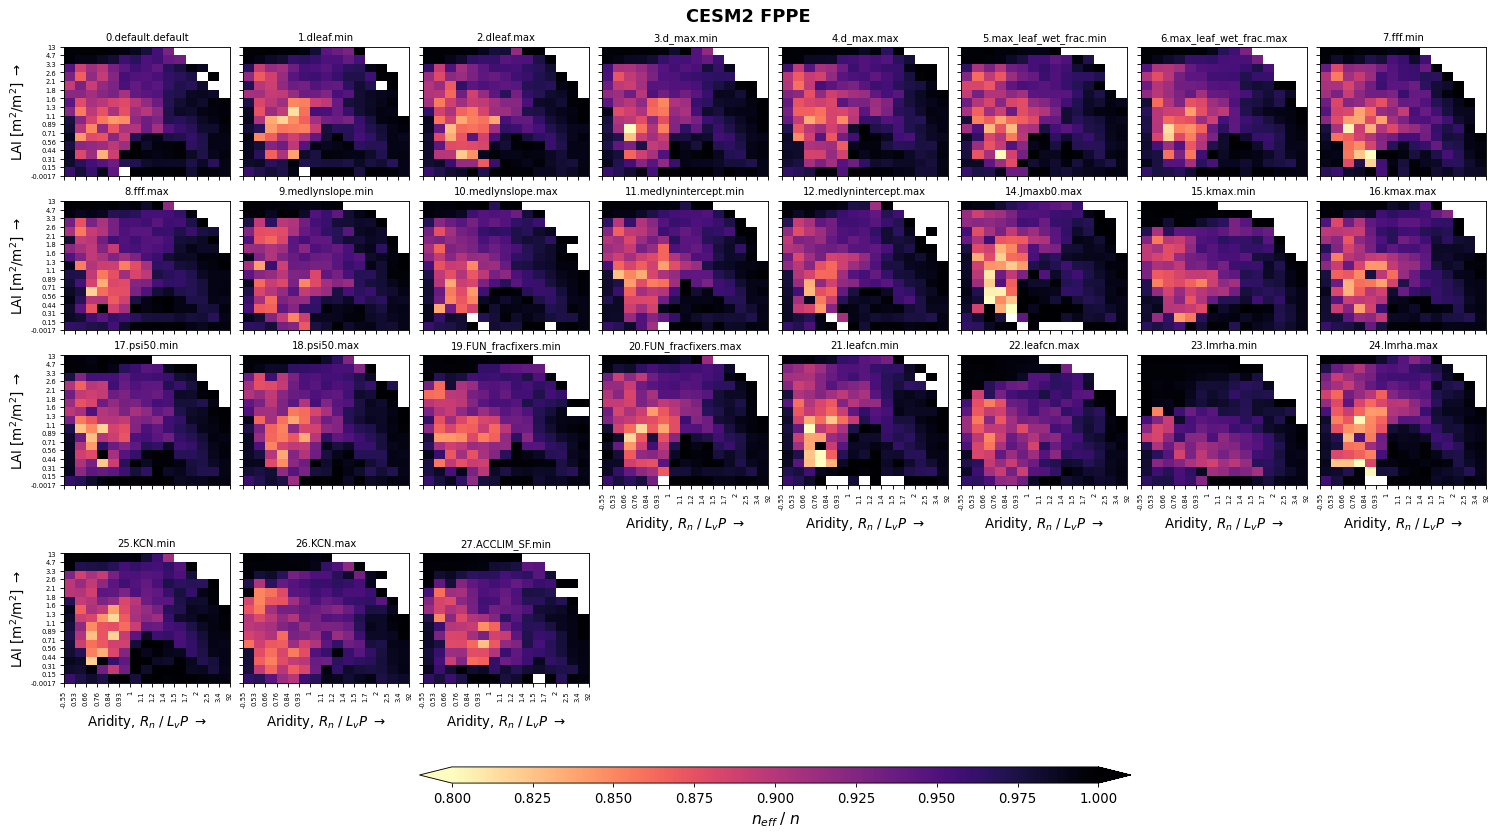

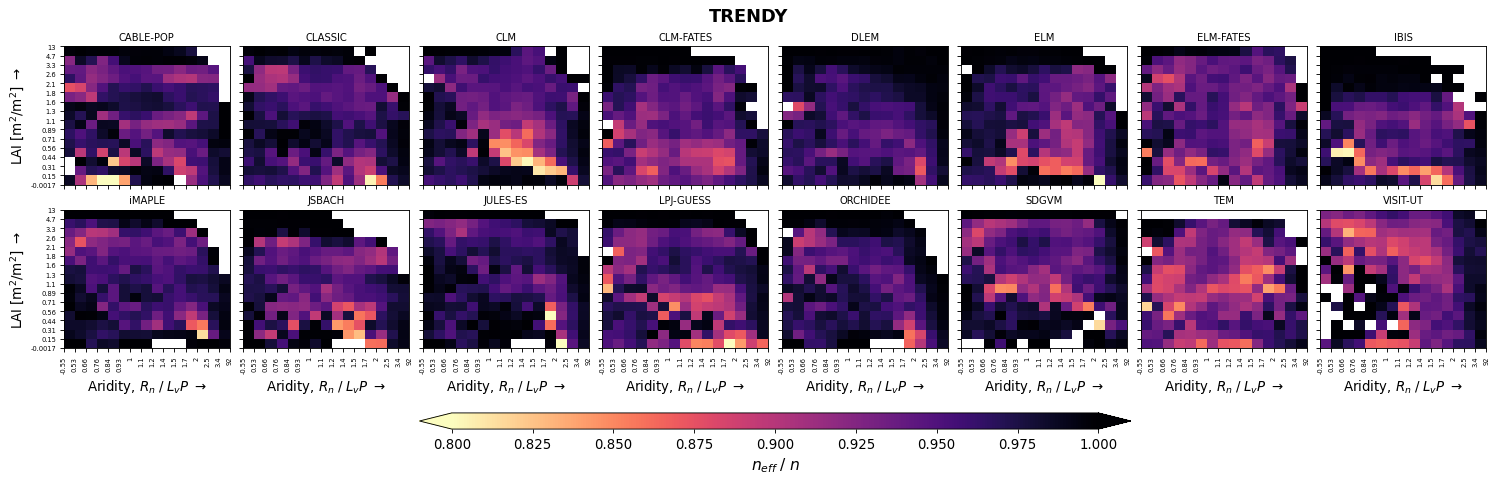

In [61]:
for f in ["obs", "cmip", "fppe", "trendy_s3"]:
    fig = member_panels(
        binned[f].sel(stats="n_eff") / binned[f].sel(stats="count"),
        f, "$n_{eff}\\;/\\;n$", 
        cmap="magma_r", vmin=0.8, vmax=1,
        dim="dataset",
    )

## 2. Test FUNCTION

In [62]:
# Observational products
mean_f_o_b = members["obs"]["FUNCTION"].mean(dim="dataset")
n_o_prod = (~np.isnan(members["obs"]["FUNCTION"])).sum(dim="dataset")
std_f_o_prod_b = members["obs"]["FUNCTION"].std(dim="dataset")
n_eff_o_b = binned["obs"].sel(stats="n_eff")
std_o_b = np.sqrt(binned["obs"].sel(stats="var_samp"))

# Model
m = "cmip"
f_m_b = binned[m].sel(stats="mean")
n_eff_m_b = binned[m].sel(stats="n_eff")
std_m_b = np.sqrt(binned[f].sel(stats="var_samp"))

# Standard errors
se_o_prod_squared = (std_f_o_prod_b ** 2) * (1 + 1 / n_o_prod)
se_o_squared = (std_o_b ** 2) * n_eff_o_b
se_m_squared = (std_m_b ** 2) * n_eff_m_b

# t-statistic
t_b = (f_m_b - mean_f_o_b) / np.sqrt(se_o_prod_squared + se_o_squared + se_m_squared)

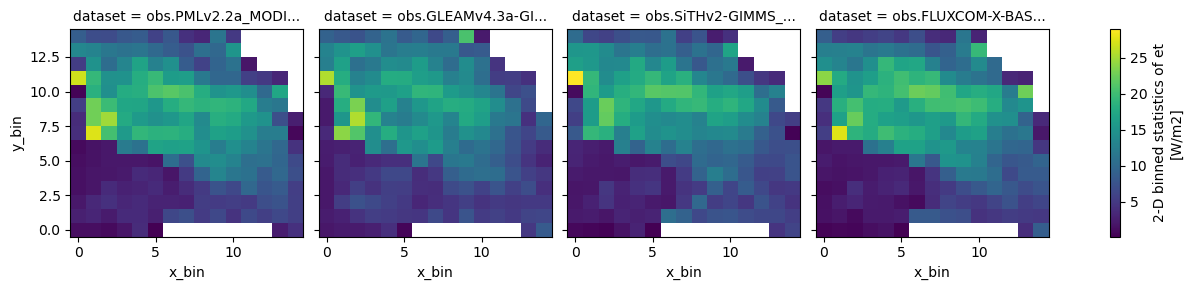

In [75]:
std_o_b.plot(col="dataset")

In [71]:
f_m_b.shape

(20, 15, 15)

In [76]:
binned["obs"]

<xarray.DataArray 'et' (dataset: 4, stats: 7, y_bin: 15, x_bin: 15)> Size: 50kB
array([[[[7.50523404e+00, 9.39437737e+00, 8.85227277e+00, ...,
                     nan, 1.03757753e+01, 1.20155150e+01],
         [8.91450881e+00, 1.17944547e+01, 1.26717896e+01, ...,
          1.90673356e+01, 1.86966205e+01, 2.03906922e+01],
         [9.69017738e+00, 1.37122454e+01, 1.37638196e+01, ...,
          2.51707820e+01, 2.66628687e+01, 2.67337671e+01],
         ...,
         [7.25911913e+01, 6.75229534e+01, 6.25355536e+01, ...,
          6.51817057e+01,            nan,            nan],
         [7.92565141e+01, 8.75020640e+01, 8.16750613e+01, ...,
                     nan,            nan,            nan],
         [1.02044232e+02, 1.05921673e+02, 1.05886044e+02, ...,
                     nan,            nan,            nan]],

        [[1.32857709e+00, 1.48411579e+00, 7.22480293e-01, ...,
                     nan, 5.60696325e+00, 1.59690688e+01],
         [6.87034761e+00, 9.20636154e+00, 4.45854131e+00, ...,
          2.94614037e+01, 4.03587060e+01, 2.99576354e+01],
         [3.76991156e+00, 1.08452386e+01, 1.70980632e+01, ...,
          4.73830180e+01, 5.61791106e+01, 3.01659097e+01],
...
          1.12509020e+04, 0.00000000e+00, 0.00000000e+00],
         [1.89255347e+05, 3.20044988e+05, 3.96931010e+05, ...,
          0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
         [4.13312222e+05, 1.75880218e+06, 1.02535021e+06, ...,
          0.00000000e+00, 0.00000000e+00, 0.00000000e+00]],

        [[2.07884252e+01, 1.69157512e+01, 7.93952024e+00, ...,
          0.00000000e+00, 1.09604310e+01, 2.46789736e+01],
         [5.91381738e+01, 1.26027183e+01, 1.37575161e+01, ...,
          7.86508982e+01, 2.55065505e+02, 3.89713020e+02],
         [1.38579350e+02, 3.23780958e+01, 4.18985713e+01, ...,
          9.07660992e+01, 2.28273043e+02, 1.60982401e+02],
         ...,
         [4.98733356e+00, 1.57646826e+01, 2.58262612e+01, ...,
          1.00000000e+00, 0.00000000e+00, 0.00000000e+00],
         [1.59533701e+01, 2.69184267e+01, 3.39173729e+01, ...,
          0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
         [3.39609937e+01, 1.42967921e+02, 8.38745013e+01, ...,
          0.00000000e+00, 0.00000000e+00, 0.00000000e+00]]]],
      shape=(4, 7, 15, 15))
Coordinates: (12/21)
  * dataset       (dataset) <U55 880B 'obs.PMLv2.2a_MODIS-GIMMS_LAI4g_V1.2-GP...
    source        (dataset) <U51 816B 'PMLv2.2a_MODIS-GIMMS_LAI4g_V1.2-GPCPv3...
    et_product    (dataset) <U14 224B 'PMLv2.2a_MODIS' ... 'FLUXCOM-X-BASE'
    lai_product   (dataset) <U16 256B 'GIMMS_LAI4g_V1.2' ... 'GIMMS_LAI4g_V1.2'
    pr_product    (dataset) <U8 128B 'GPCPv3.3' 'GPCPv3.3' 'GPCPv3.3' 'GPCPv3.3'
    rn_product    (dataset) <U10 160B 'CERESed4.2' 'CERESed4.2' ... 'CERESed4.2'
    ...            ...
    x_bin_lower   (x_bin) float64 120B -0.546 0.5261 0.6624 ... 2.473 3.381
    x_bin_upper   (x_bin) float64 120B 0.5261 0.6624 0.7589 ... 3.381 91.71
    x_bin_center  (x_bin) float64 120B -0.009935 0.5942 0.7106 ... 2.927 47.54
    x_bin_label   (x_bin) <U8 480B 'Q0-Q7' 'Q7-Q13' ... 'Q87-Q93' 'Q93-Q100'
    ltype         int64 8B 4
    landunit      <U40 160B 'ltype_landice_multiple_elevation_classes'
Attributes: (12/19)
    long_name:    2-D binned statistics of et
    units:        W/m2
    y_variable:   lai
    x_variable:   ai
    y_strategy:   quantile
    x_strategy:   quantile
    ...           ...
    time_period:  200101-201412
    grid:         1deg
    run_id:       r38cf3df
    n_members:    4
    area_mask:    /glade/work/bbuchovecky/et_unc/proc/r38cf3df/all/mask/all.a...
    et_samples:   climatological annual mean ET, one sample per gridcell